In [3]:
#The packages needed are imported
import fastf1 as ff1
from fastf1 import plotting
from matplotlib import pyplot as plt
from matplotlib.pyplot import figure
import numpy as np
import pandas as pd

In [4]:
#Create a cache directory
import os

cache_dir = os.path.join(os.getcwd(), 'cache')
if not os.path.exists(cache_dir):
    os.mkdir(cache_dir)

# 1) Getting the data from Webscrapping and APIs

In [6]:
# Enable the cache
ff1.Cache.enable_cache(cache_dir)

In [5]:
import pandas as pd
import numpy as np
import requests

# query API

races = {'season': [],
        'round': [],
        'circuit_id': [],
        'country': [],
        'date': []}

#We only take years from the hybrid era

for year in list(range(2014,2022)):
    
    url = 'https://ergast.com/api/f1/{}.json'
    r = requests.get(url.format(year))
    json = r.json()

    for item in json['MRData']['RaceTable']['Races']:
        try:
            races['season'].append(int(item['season']))
        except:
            races['season'].append(None)

        try:
            races['round'].append(int(item['round']))
        except:
            races['round'].append(None)

        try:
            races['circuit_id'].append(item['Circuit']['circuitId'])
        except:
            races['circuit_id'].append(None)

        try:
            races['country'].append(item['Circuit']['Location']['country'])
        except:
            races['country'].append(None)

        try:
            races['date'].append(item['date'])
        except:
            races['date'].append(None)

        
races = pd.DataFrame(races)
races

,season,round,circuit_id,country,date
0,2014,1,albert_park,Australia,2014-03-16
1,2014,2,sepang,Malaysia,2014-03-30
2,2014,3,bahrain,Bahrain,2014-04-06
3,2014,4,shanghai,China,2014-04-20
4,2014,5,catalunya,Spain,2014-05-11
...,...,...,...,...,...
155,2021,18,rodriguez,Mexico,2021-11-07
156,2021,19,interlagos,Brazil,2021-11-14
157,2021,20,losail,Qatar,2021-11-21
158,2021,21,jeddah,Saudi Arabia,2021-12-05


In [6]:
# Print the data types of each element in the dataframe
for i in races.columns:
    print(races[i].dtype)

int64
int64
object
object
object


In [7]:
# Create a list of tuples containing the year and the rounds for each season
rounds = [(year, races[races.season == year]['round'].tolist())
          for year in races.season.unique()]

# Query the API and store the results in a list of dictionaries
results = []
for year, year_rounds in rounds:
    for rnd in year_rounds:
        url = f'http://ergast.com/api/f1/{year}/{rnd}/results.json'
        response = requests.get(url)
        race = response.json()['MRData']['RaceTable']['Races'][0]

        for result in race['Results']:
            result_dict = {
                'season': int(race['season']),
                'round': int(race['round']),
                'circuit_id': race['Circuit']['circuitId'],
                'driver': result['Driver']['driverId'],
                'date_of_birth': result['Driver']['dateOfBirth'],
                'nationality': result['Driver']['nationality'],
                'constructor': result['Constructor']['constructorId'],
                'grid': int(result.get('grid', -1)),
                'time': int(result['Time']['millis']) if result.get('Time') else None,
                'status': result['status'],
                'points': float(result.get('points', -1)),
                'rank': int(result.get('position', -1))
            }
            results.append(result_dict)


            
# Convert the list of dictionaries to a pandas DataFrame
results = pd.DataFrame(results)
results

,season,round,circuit_id,driver,date_of_birth,nationality,constructor,grid,time,status,points,rank
0,2014,1,albert_park,rosberg,1985-06-27,German,mercedes,3,5578710.0,Finished,25.0,1
1,2014,1,albert_park,kevin_magnussen,1992-10-05,Danish,mclaren,4,5605487.0,Finished,18.0,2
2,2014,1,albert_park,button,1980-01-19,British,mclaren,10,5608737.0,Finished,15.0,3
3,2014,1,albert_park,alonso,1981-07-29,Spanish,ferrari,5,5613994.0,Finished,12.0,4
4,2014,1,albert_park,bottas,1989-08-28,Finnish,williams,15,5626349.0,Finished,10.0,5
...,...,...,...,...,...,...,...,...,...,...,...,...
3262,2021,22,yas_marina,latifi,1995-06-29,Canadian,williams,16,NaN,Accident,0.0,16
3263,2021,22,yas_marina,giovinazzi,1993-12-14,Italian,alfa,14,NaN,Gearbox,0.0,17
3264,2021,22,yas_marina,russell,1998-02-15,British,williams,17,NaN,Gearbox,0.0,18
3265,2021,22,yas_marina,raikkonen,1979-10-17,Finnish,alfa,18,NaN,Brakes,0.0,19


In [9]:
# Print the data types of each element in the dataframe
for i in results.columns:
    print(results[i].dtype)

int64
int64
object
object
object
object
object
int64
float64
object
float64
int64


In [10]:
import bs4
import pandas as pd
from bs4 import BeautifulSoup
import requests

qualifying_results = pd.DataFrame()

for year in range(2014, 2022):
    url = f'https://www.formula1.com/en/results.html/{year}/races.html'
    r = requests.get(url)
    soup = BeautifulSoup(r.text, 'html.parser')

    year_links = [link.get('href') for link in soup.find_all('a', class_='resultsarchive-filter-item-link FilterTrigger') if f'/en/results.html/{year}/races/' in link.get('href')]

    year_df = pd.concat([pd.read_html(f'https://www.formula1.com{link.replace("race-result.html", "starting-grid.html")}')[0].assign(season=year, round=n + 1) for n, link in enumerate(year_links)], ignore_index=True)

    qualifying_results = pd.concat([qualifying_results, year_df], ignore_index=True)

qualifying_results.rename(columns={'Pos': 'grid', 'Driver': 'driver_name', 'Car': 'car', 'Time': 'qualifying_time'}, inplace=True)
qualifying_results.drop('No', axis=1, inplace=True)
qualifying_results

,Unnamed: 0,grid,driver_name,car,qualifying_time,Unnamed: 6,season,round,Unnamed: 5
0,NaN,1,Lewis Hamilton HAM,Mercedes,1:44.231,NaN,2014,1,NaN
1,NaN,2,Daniel Ricciardo RIC,Red Bull Racing Renault,1:44.548,NaN,2014,1,NaN
2,NaN,3,Nico Rosberg ROS,Mercedes,1:44.595,NaN,2014,1,NaN
3,NaN,4,Kevin Magnussen MAG,McLaren Mercedes,1:45.745,NaN,2014,1,NaN
4,NaN,5,Fernando Alonso ALO,Ferrari,1:45.819,NaN,2014,1,NaN
...,...,...,...,...,...,...,...,...,...
3224,NaN,15,Sebastian Vettel VET,Aston Martin Mercedes,1:24.305,NaN,2021,22,NaN
3225,NaN,16,Nicholas Latifi LAT,Williams Mercedes,1:24.338,NaN,2021,22,NaN
3226,NaN,17,George Russell RUS,Williams Mercedes,1:24.423,NaN,2021,22,NaN
3227,NaN,18,Kimi Räikkönen RAI,Alfa Romeo Racing Ferrari,1:24.779,NaN,2021,22,NaN


In [189]:
qualifying_results = qualifying_results.drop('Unnamed: 5', axis=1)
qualifying_results = qualifying_results.drop('Unnamed: 0', axis=1)
qualifying_results = qualifying_results.drop('Unnamed: 6', axis=1)
qualifying_results

,grid,driver_name,car,qualifying_time,season,round
0,1,Lewis Hamilton HAM,Mercedes,1:44.231,2014,1
1,2,Daniel Ricciardo RIC,Red Bull Racing Renault,1:44.548,2014,1
2,3,Nico Rosberg ROS,Mercedes,1:44.595,2014,1
3,4,Kevin Magnussen MAG,McLaren Mercedes,1:45.745,2014,1
4,5,Fernando Alonso ALO,Ferrari,1:45.819,2014,1
...,...,...,...,...,...,...
3224,15,Sebastian Vettel VET,Aston Martin Mercedes,1:24.305,2021,22
3225,16,Nicholas Latifi LAT,Williams Mercedes,1:24.338,2021,22
3226,17,George Russell RUS,Williams Mercedes,1:24.423,2021,22
3227,18,Kimi Räikkönen RAI,Alfa Romeo Racing Ferrari,1:24.779,2021,22


In [15]:
# Print the data types of each element in the dataframe
for i in qualifying_results.columns:
    print(qualifying_results[i].dtype)

float64
int64
object
object
object
float64
int64
int64
float64


In [12]:
# Let's calculate the win ratio of each driver during the turbo hybride era (2014-2020)

p1 = results[results['rank'] == 1]['driver'].value_counts()
number_gp= len(races)


win_ratio=p1/number_gp
all_drivers = results['driver'].unique()  # get all unique drivers
all_drivers_counts = pd.Series(0, index=all_drivers)  # create a new series with counts initialized to 0
p1ratio = p1.combine(all_drivers_counts, lambda x, y: x / number_gp if x > 0 else y)  # add missing drivers with a ratio of 0

new_column = p1ratio.rename('P1driverRatio')
race_result = results.merge(new_column, left_on='driver', right_index=True)
race_result

,season,round,circuit_id,driver,date_of_birth,nationality,constructor,grid,time,status,points,rank,P1driverRatio
0,2014,1,albert_park,rosberg,1985-06-27,German,mercedes,3,5578710.0,Finished,25.0,1,0.125
23,2014,2,sepang,rosberg,1985-06-27,German,mercedes,3,6043287.0,Finished,18.0,2,0.125
45,2014,3,bahrain,rosberg,1985-06-27,German,mercedes,1,5983828.0,Finished,18.0,2,0.125
67,2014,4,shanghai,rosberg,1985-06-27,German,mercedes,4,5626400.0,Finished,18.0,2,0.125
89,2014,5,catalunya,rosberg,1985-06-27,German,mercedes,2,6065791.0,Finished,18.0,2,0.125
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3184,2021,18,rodriguez,mazepin,1999-03-02,Russian,haas,15,NaN,+3 Laps,0.0,18,0.000
3203,2021,19,interlagos,mazepin,1999-03-02,Russian,haas,19,NaN,+2 Laps,0.0,17,0.000
3224,2021,20,losail,mazepin,1999-03-02,Russian,haas,20,NaN,+2 Laps,0.0,18,0.000
3244,2021,21,jeddah,mazepin,1999-03-02,Russian,haas,20,NaN,Collision,0.0,18,0.000


In [13]:
driver_standings = {
    'season': [],
    'round': [],
    'driver': [],
    'driver_points': [],
    'driver_wins': [],
    'driver_standings_pos': []
}

# Query API to fetch driver standings data
for year in range(2014, 2022):
    url = f"https://ergast.com/api/f1/{year}.json"
    r = requests.get(url)
    json_data = r.json()

    total_rounds = int(json_data['MRData']['total'])
    rounds = range(1, total_rounds + 1)

    for rnd in rounds:
        url = f"https://ergast.com/api/f1/{year}/{rnd}/driverStandings.json"
        r = requests.get(url)
        json_data = r.json()

        for item in json_data['MRData']['StandingsTable']['StandingsLists'][0]['DriverStandings']:
            driver_standings['season'].append(int(year))
            driver_standings['round'].append(int(rnd))
            driver_standings['driver'].append(item['Driver']['driverId'])
            driver_standings['driver_points'].append(round(float(item['points'])))
            driver_standings['driver_wins'].append(int(item['wins']))
            driver_standings['driver_standings_pos'].append(int(item['position']))

driver_standings = pd.DataFrame(driver_standings)

# Define lookup function to shift points and number of wins from previous rounds
def lookup(df, team, points):
    df['lookup1'] = df.season.astype(str) + df[team] + df['round'].astype(str)
    df['lookup2'] = df.season.astype(str) + df[team] + (df['round']-1).astype(str)
    new_df = df.merge(df[['lookup1', points]], how='left', left_on='lookup2', right_on='lookup1')
    new_df.drop(['lookup1_x', 'lookup2', 'lookup1_y'], axis=1, inplace=True)
    new_df.rename(columns={points+'_x': points+'_after_race', points+'_y': points}, inplace=True)
    new_df[points].fillna(0, inplace=True)
    return new_df

driver_standings = lookup(driver_standings, 'driver', 'driver_points')
driver_standings = lookup(driver_standings, 'driver', 'driver_wins')
driver_standings = lookup(driver_standings, 'driver', 'driver_standings_pos')

driver_standings.drop(['driver_points_after_race', 'driver_wins_after_race', 'driver_standings_pos_after_race'], 
                      axis=1, inplace=True)


driver_standings

,season,round,driver,driver_points,driver_wins,driver_standings_pos
0,2014,1,rosberg,0.0,0.0,0.0
1,2014,1,kevin_magnussen,0.0,0.0,0.0
2,2014,1,button,0.0,0.0,0.0
3,2014,1,alonso,0.0,0.0,0.0
4,2014,1,bottas,0.0,0.0,0.0
...,...,...,...,...,...,...
3417,2021,22,latifi,7.0,0.0,17.0
3418,2021,22,giovinazzi,3.0,0.0,18.0
3419,2021,22,mick_schumacher,0.0,0.0,19.0
3420,2021,22,kubica,0.0,0.0,20.0


In [186]:
# Print the data types of each element in the dataframe
for i in driver_standings.columns:
    print(driver_standings[i].dtype)

int64
int64
object
float64
float64
float64


2) Preprocessing the data

In [16]:
# Pre Process the datasets and merge

#first we are going to preprocess qualifying_results by deleting Unnamed: 0 and Unnamed: 6

qualifying_results = qualifying_results.drop('Unnamed: 5', axis=1)

# Let's add a column 'gap' to our dataframe that will display the gap between P1 and other drivers

# merge all the df to get one df with all the informations


df1 = pd.merge(races, race_result, how='inner', 
               on=['season', 'round', 'circuit_id']).drop(['points', 'time'], 
                                                                 axis = 1)
df2 = pd.merge(df1, driver_standings, how='left', 
               on=['season', 'round', 'driver']) 

df = pd.merge(df2, qualifying_results, how='inner', 
                    on=['season', 'round', 'grid']).drop(['driver_name', 'car'], 
                                                         axis = 1) 

df

,season,round,circuit_id,country,date,driver,date_of_birth,nationality,constructor,grid,status,rank,P1driverRatio,driver_points,driver_wins,driver_standings_pos,Unnamed: 0,qualifying_time,Unnamed: 6
0,2014,1,albert_park,Australia,2014-03-16,rosberg,1985-06-27,German,mercedes,3,Finished,1,0.1250,0.0,0.0,0.0,NaN,1:44.595,NaN
1,2014,1,albert_park,Australia,2014-03-16,kevin_magnussen,1992-10-05,Danish,mclaren,4,Finished,2,0.0000,0.0,0.0,0.0,NaN,1:45.745,NaN
2,2014,1,albert_park,Australia,2014-03-16,button,1980-01-19,British,mclaren,10,Finished,3,0.0000,0.0,0.0,0.0,NaN,1:44.437,NaN
3,2014,1,albert_park,Australia,2014-03-16,alonso,1981-07-29,Spanish,ferrari,5,Finished,4,0.0000,0.0,0.0,0.0,NaN,1:45.819,NaN
4,2014,1,albert_park,Australia,2014-03-16,bottas,1989-08-28,Finnish,williams,15,Finished,5,0.0625,0.0,0.0,0.0,NaN,1:48.147,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3198,2021,22,yas_marina,UAE,2021-12-12,norris,1999-11-13,British,mclaren,3,Finished,7,0.0000,154.0,0.0,6.0,NaN,1:22.931,NaN
3199,2021,22,yas_marina,UAE,2021-12-12,russell,1998-02-15,British,williams,17,Gearbox,18,0.0000,16.0,0.0,15.0,NaN,1:24.423,NaN
3200,2021,22,yas_marina,UAE,2021-12-12,latifi,1995-06-29,Canadian,williams,16,Accident,16,0.0000,7.0,0.0,17.0,NaN,1:24.338,NaN
3201,2021,22,yas_marina,UAE,2021-12-12,tsunoda,2000-05-11,Japanese,alphatauri,8,Finished,4,0.0000,20.0,0.0,14.0,NaN,1:23.220,NaN


In [17]:
# calculate difference in qualifying times
#check for the colon separator (:) in the string value of qualifying_time before attempting to split it. If the separator is not present, the value of qualifying_time is set to 0.

df['qualifying_time'] = df.qualifying_time.map(lambda x: 0 if str(x) == '00.000'
                             else(float(str(x).split(':')[1]) + 
                                  (60 * float(str(x).split(':')[0])) if ':' in str(x) else 0))
df = df[df['qualifying_time'] != 0]
df.sort_values(['season', 'round', 'grid'], inplace = True)
df['qualifying_time_diff'] = df.groupby(['season', 'round']).qualifying_time.diff()
df['qualifying_time'] = df.groupby(['season', 
                                                'round']).qualifying_time_diff.cumsum().fillna(0)
#df.drop('qualifying_time_diff', axis = 1, inplace = True)
df

/var/folders/81/tyt5gxcs48zfmfdm655lz3q40000gn/T/ipykernel_10773/837571339.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.sort_values(['season', 'round', 'grid'], inplace = True)
/var/folders/81/tyt5gxcs48zfmfdm655lz3q40000gn/T/ipykernel_10773/837571339.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['qualifying_time_diff'] = df.groupby(['season', 'round']).qualifying_time.diff()
/var/folders/81/tyt5gxcs48zfmfdm655lz3q40000gn/T/ipykernel_10773/837571339.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFram

,season,round,circuit_id,country,date,driver,date_of_birth,nationality,constructor,grid,status,rank,P1driverRatio,driver_points,driver_wins,driver_standings_pos,Unnamed: 0,qualifying_time,Unnamed: 6,qualifying_time_diff
17,2014,1,albert_park,Australia,2014-03-16,hamilton,1985-01-07,British,mercedes,1,Engine,19,0.50625,0.0,0.0,0.0,NaN,0.000,NaN,NaN
20,2014,1,albert_park,Australia,2014-03-16,ricciardo,1989-07-01,Australian,red_bull,2,Disqualified,22,0.05000,0.0,0.0,0.0,NaN,0.317,NaN,0.317
0,2014,1,albert_park,Australia,2014-03-16,rosberg,1985-06-27,German,mercedes,3,Finished,1,0.12500,0.0,0.0,0.0,NaN,0.364,NaN,0.047
1,2014,1,albert_park,Australia,2014-03-16,kevin_magnussen,1992-10-05,Danish,mclaren,4,Finished,2,0.00000,0.0,0.0,0.0,NaN,1.514,NaN,1.150
3,2014,1,albert_park,Australia,2014-03-16,alonso,1981-07-29,Spanish,ferrari,5,Finished,4,0.00000,0.0,0.0,0.0,NaN,1.588,NaN,0.074
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3188,2021,22,yas_marina,UAE,2021-12-12,vettel,1987-07-03,German,aston_martin,15,Finished,11,0.08750,43.0,0.0,12.0,NaN,2.196,NaN,0.054
3200,2021,22,yas_marina,UAE,2021-12-12,latifi,1995-06-29,Canadian,williams,16,Accident,16,0.00000,7.0,0.0,17.0,NaN,2.229,NaN,0.033
3199,2021,22,yas_marina,UAE,2021-12-12,russell,1998-02-15,British,williams,17,Gearbox,18,0.00000,16.0,0.0,15.0,NaN,2.314,NaN,0.085
3186,2021,22,yas_marina,UAE,2021-12-12,raikkonen,1979-10-17,Finnish,alfa,18,Brakes,19,0.00625,10.0,0.0,16.0,NaN,2.670,NaN,0.356


In [31]:
df = df.rename(columns={'qualifying_time': 'quali_gap'})
df = df.drop('qualifying_time_diff',axis=1)

KeyError: "['qualifying_time_diff'] not found in axis"

We have 2776 observations, let's do some quick calulation to see if we have the good number of observations or if there are more informations or less and how can we explain it. 
We do : Number of races in a year x Number of drivers this year

--> 2014 : 19 races / 23 Drivers (11 teams)

--> 2015 : 19 races / 21 Drivers (10 teams)

--> 2016 : 21 races / 24 Drivers (11 teams)

--> 2017 : 20 races / 23 Drivers (10 teams)

--> 2018 : 21 races / 20 Drivers (10 teams)

--> 2019 : 21 races / 20 Drivers (10 teams)

--> 2020 : 17 races / 23 Drivers (10 teams) Covid Year

--> 2021 : 22 races / 21 Drivers (10 teams)

Total number of races x drivers over the years: 3,593

So there are almost 1,000 data missing 

In [88]:
# Let's drop all the NaN values of the Dataframe
columns=['driver_points', 'driver_wins', 'driver_standings_pos']
for column in columns:
    df[column].fillna(0, inplace = True)
    df[column] = df[column].map(lambda x: int(x))
df.dropna(inplace = True )

In [89]:
df

,season,round,circuit_id,country,date,driver,date_of_birth,nationality,constructor,grid,status,rank,P1driverRatio,driver_points,driver_wins,driver_standings_pos,quali_gap
17,2014,1,albert_park,Australia,2014-03-16,hamilton,1985-01-07,British,mercedes,1,Engine,19,0.50625,0,0,0,0.000
20,2014,1,albert_park,Australia,2014-03-16,ricciardo,1989-07-01,Australian,red_bull,2,Disqualified,22,0.05000,0,0,0,0.317
0,2014,1,albert_park,Australia,2014-03-16,rosberg,1985-06-27,German,mercedes,3,Finished,1,0.12500,0,0,0,0.364
1,2014,1,albert_park,Australia,2014-03-16,kevin_magnussen,1992-10-05,Danish,mclaren,4,Finished,2,0.00000,0,0,0,1.514
3,2014,1,albert_park,Australia,2014-03-16,alonso,1981-07-29,Spanish,ferrari,5,Finished,4,0.00000,0,0,0,1.588
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3188,2021,22,yas_marina,UAE,2021-12-12,vettel,1987-07-03,German,aston_martin,15,Finished,11,0.08750,43,0,12,2.196
3200,2021,22,yas_marina,UAE,2021-12-12,latifi,1995-06-29,Canadian,williams,16,Accident,16,0.00000,7,0,17,2.229
3199,2021,22,yas_marina,UAE,2021-12-12,russell,1998-02-15,British,williams,17,Gearbox,18,0.00000,16,0,15,2.314
3186,2021,22,yas_marina,UAE,2021-12-12,raikkonen,1979-10-17,Finnish,alfa,18,Brakes,19,0.00625,10,0,16,2.670


In [18]:
print(min(df['driver_age']))

KeyError: 'driver_age'

We went from 2776 bservations to 2663 observations

We have collected the data by web scrapping and using an F1 API, and then we have pre processed our dataframes. 
We end up with four different dataframe which I have to merge together using common keys. My final dataframe includes information of races, results, driver standings and qualifying times from 2014 to 2021

In another Notebook I have done some Data Analyses.

We can now start the Machine Learning Part.

# 3) Machine Learning

# a) Preprocess data for machine learning

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import sklearn.metrics as sk_met
import sys

Machine Learning algorithms only works with numerical data. Float64 or Int, we thus have to check the type of our data

In [20]:
df.dtypes

season                    int64
round                     int64
circuit_id               object
country                  object
date                     object
driver                   object
date_of_birth            object
nationality              object
constructor              object
grid                      int64
status                   object
rank                      int64
P1driverRatio           float64
driver_points           float64
driver_wins             float64
driver_standings_pos    float64
Unnamed: 0              float64
qualifying_time         float64
Unnamed: 6              float64
qualifying_time_diff    float64
dtype: object

We have some int64,int64 but also some object type. Machine learning algorithms can't work with data that are objects. So we now have to figure out how we can use columns that are not numeric. 

In [21]:
df['date']=pd.to_datetime(df['date'])

/var/folders/81/tyt5gxcs48zfmfdm655lz3q40000gn/T/ipykernel_10773/1213281828.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['date']=pd.to_datetime(df['date'])


Now let's convert some data that are objects into dummy variables so we can use it for our machine learning algorithm.
We have seen through our graphs that Mercedes, Ferrari and Red Bull are the best teams in this era, therefore being in one of these teams will give the driver a much bigger chance to win a race. 
If a driver is in one of these teams we will alocate it to 1 and if not 0. 

In [22]:
df['Top Team'] = df['constructor'].apply(lambda x: 1 if x in ['ferrari', 'mercedes', 'red_bull'] else 0)
df['team_id']=df['constructor'].astype('category').cat.codes

/var/folders/81/tyt5gxcs48zfmfdm655lz3q40000gn/T/ipykernel_10773/4128516767.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Top Team'] = df['constructor'].apply(lambda x: 1 if x in ['ferrari', 'mercedes', 'red_bull'] else 0)
/var/folders/81/tyt5gxcs48zfmfdm655lz3q40000gn/T/ipykernel_10773/4128516767.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['team_id']=df['constructor'].astype('category').cat.codes


Now let's give a numerical id to each F1 circuit

In [23]:
df['numerical_circuit_id']=df['circuit_id'].astype('category').cat.codes

/var/folders/81/tyt5gxcs48zfmfdm655lz3q40000gn/T/ipykernel_10773/2583230436.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['numerical_circuit_id']=df['circuit_id'].astype('category').cat.codes


There are 28 Circuit ID which means that there is a total of 28 circuits

In [24]:
from dateutil.relativedelta import *
df['date'] = pd.to_datetime(df.date)
df['date_of_birth'] = pd.to_datetime(df.date_of_birth)
df['driver_age'] = df.apply(lambda x: 
                                        relativedelta(x['date'], x['date_of_birth']).years, axis=1)
df.drop(['date_of_birth'], axis = 1, inplace = True)
df

/var/folders/81/tyt5gxcs48zfmfdm655lz3q40000gn/T/ipykernel_10773/3864309160.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['date'] = pd.to_datetime(df.date)
/var/folders/81/tyt5gxcs48zfmfdm655lz3q40000gn/T/ipykernel_10773/3864309160.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['date_of_birth'] = pd.to_datetime(df.date_of_birth)
/var/folders/81/tyt5gxcs48zfmfdm655lz3q40000gn/T/ipykernel_10773/3864309160.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a D

,season,round,circuit_id,country,date,driver,nationality,constructor,grid,status,...,driver_wins,driver_standings_pos,Unnamed: 0,qualifying_time,Unnamed: 6,qualifying_time_diff,Top Team,team_id,numerical_circuit_id,driver_age
17,2014,1,albert_park,Australia,2014-03-16,hamilton,British,mercedes,1,Engine,...,0.0,0.0,NaN,0.000,NaN,NaN,1,12,0,29
20,2014,1,albert_park,Australia,2014-03-16,ricciardo,Australian,red_bull,2,Disqualified,...,0.0,0.0,NaN,0.317,NaN,0.317,1,14,0,24
0,2014,1,albert_park,Australia,2014-03-16,rosberg,German,mercedes,3,Finished,...,0.0,0.0,NaN,0.364,NaN,0.047,1,12,0,28
1,2014,1,albert_park,Australia,2014-03-16,kevin_magnussen,Danish,mclaren,4,Finished,...,0.0,0.0,NaN,1.514,NaN,1.150,0,11,0,21
3,2014,1,albert_park,Australia,2014-03-16,alonso,Spanish,ferrari,5,Finished,...,0.0,0.0,NaN,1.588,NaN,0.074,1,5,0,32
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3188,2021,22,yas_marina,UAE,2021-12-12,vettel,German,aston_martin,15,Finished,...,0.0,12.0,NaN,2.196,NaN,0.054,0,3,28,34
3200,2021,22,yas_marina,UAE,2021-12-12,latifi,Canadian,williams,16,Accident,...,0.0,17.0,NaN,2.229,NaN,0.033,0,18,28,26
3199,2021,22,yas_marina,UAE,2021-12-12,russell,British,williams,17,Gearbox,...,0.0,15.0,NaN,2.314,NaN,0.085,0,18,28,23
3186,2021,22,yas_marina,UAE,2021-12-12,raikkonen,Finnish,alfa,18,Brakes,...,0.0,16.0,NaN,2.670,NaN,0.356,0,0,28,42


Lastly we create a driver id for each driver. 

In [25]:
df['driver_id']=df['driver'].astype('category').cat.codes

/var/folders/81/tyt5gxcs48zfmfdm655lz3q40000gn/T/ipykernel_10773/975547669.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['driver_id']=df['driver'].astype('category').cat.codes


In [26]:
# create new column with 1 for 'finished' and 0 otherwise
df['status_id'] = df['status'].apply(lambda x: 1 if x == 'Finished' else 0)

/var/folders/81/tyt5gxcs48zfmfdm655lz3q40000gn/T/ipykernel_10773/1983812472.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['status_id'] = df['status'].apply(lambda x: 1 if x == 'Finished' else 0)


In [27]:
df.dtypes

season                           int64
round                            int64
circuit_id                      object
country                         object
date                    datetime64[ns]
driver                          object
nationality                     object
constructor                     object
grid                             int64
status                          object
rank                             int64
P1driverRatio                  float64
driver_points                  float64
driver_wins                    float64
driver_standings_pos           float64
Unnamed: 0                     float64
qualifying_time                float64
Unnamed: 6                     float64
qualifying_time_diff           float64
Top Team                         int64
team_id                           int8
numerical_circuit_id              int8
driver_age                       int64
driver_id                         int8
status_id                        int64
dtype: object

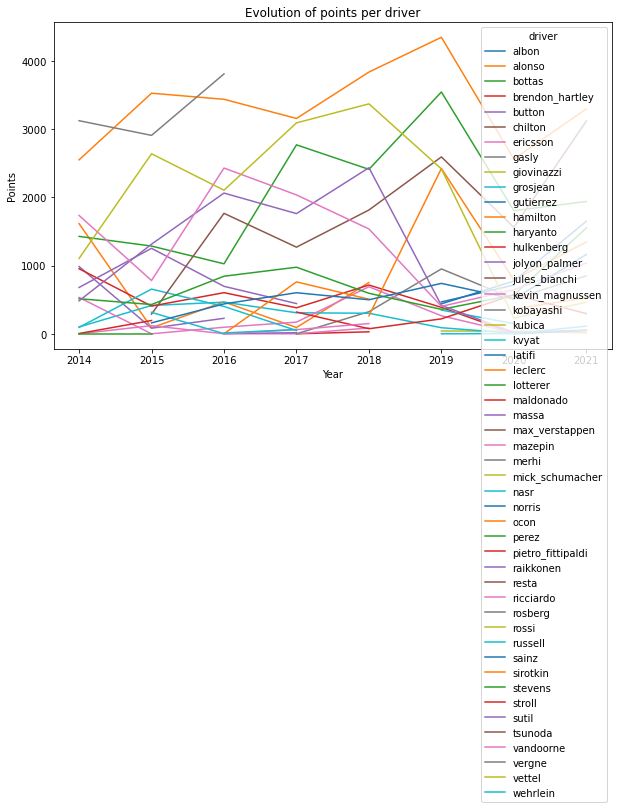

In [193]:
import pandas as pd
import matplotlib.pyplot as plt


# Group by year and driver, and sum the points for each group
points_by_year_and_driver = df.groupby(['season', 'driver'])['driver_points'].sum()

# Pivot the table to get each driver's points as a separate column
points_by_driver_and_year = points_by_year_and_driver.unstack(level='driver')

# Plot the data
points_by_driver_and_year.plot(figsize=(10, 6))

# Add axis labels and a title
plt.xlabel('Year')
plt.ylabel('Points')
plt.title('Evolution of points per driver')
plt.show()

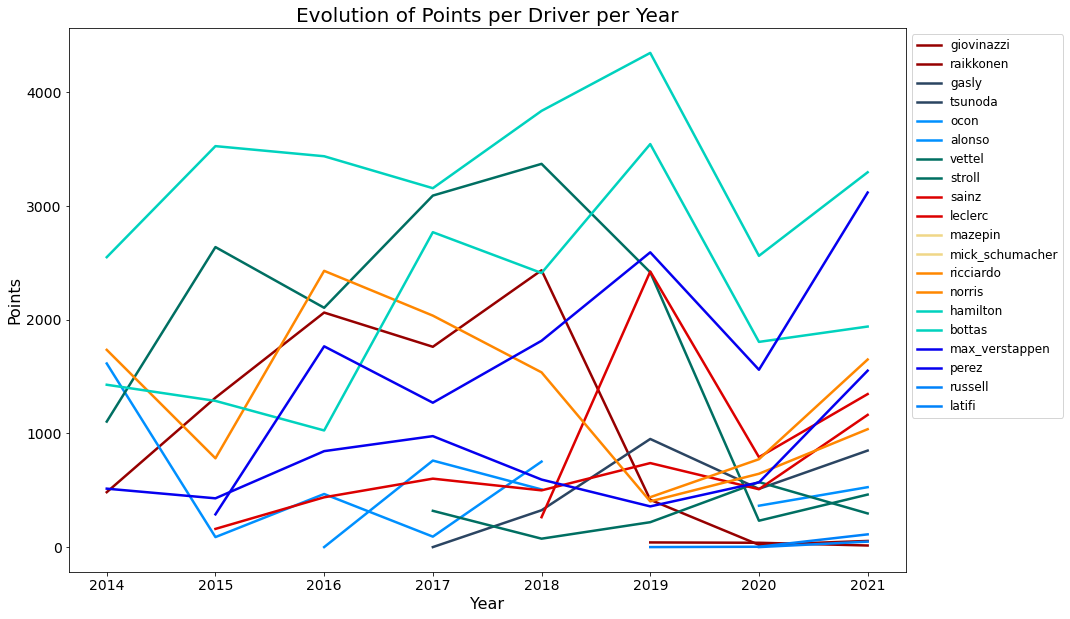

In [199]:
import pandas as pd
import matplotlib.pyplot as plt

# Define the colors for each driver
colors = {
    'giovinazzi': '#960000',
    'raikkonen': '#960000',
    'gasly': '#2B4562',
    'tsunoda': '#2B4562',
    'ocon': '#0090FF',
    'alonso': '#0090FF',
    'vettel': '#006F62',
    'stroll': '#006F62',
    'sainz': '#DC0000',
    'leclerc': '#DC0000',
    'mazepin': '#F0D787',
    'mick_schumacher': '#F0D787',
    'ricciardo': '#FF8700',
    'norris': '#FF8700',
    'hamilton': '#00D2BE',
    'bottas': '#00D2BE',
    'max_verstappen': '#0600EF',
    'perez': '#0600EF',
    'russell': '#0082FA',
    'latifi': '#0082FA',
}


# Calculate the total points for each driver in each season
driver_points = df.groupby(['season', 'driver'])['driver_points'].sum().unstack()

# Only keep the drivers we want to plot
drivers_to_plot = list(colors.keys())
driver_points = driver_points[drivers_to_plot]

# Plot the graph
fig, ax = plt.subplots(figsize=(15, 10))
driver_points.plot(ax=ax, color=colors.values(), linewidth=2.5)

# Set the title and axis labels
ax.set_title('Evolution of Points per Driver per Year', fontsize=20)
ax.set_xlabel('Year', fontsize=16)
ax.set_ylabel('Points', fontsize=16)

# Set the tick labels font size
ax.tick_params(axis='both', which='major', labelsize=14)

# Add a legend
ax.legend(fontsize=12, loc='upper left', bbox_to_anchor=(1, 1))

# Show the plot
plt.show()

/opt/anaconda3/lib/python3.9/site-packages/numpy/lib/function_base.py:2683: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/opt/anaconda3/lib/python3.9/site-packages/numpy/lib/function_base.py:2542: RuntimeWarning: divide by zero encountered in true_divide
  c *= np.true_divide(1, fact)
/opt/anaconda3/lib/python3.9/site-packages/numpy/lib/function_base.py:2683: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/opt/anaconda3/lib/python3.9/site-packages/numpy/lib/function_base.py:2542: RuntimeWarning: divide by zero encountered in true_divide
  c *= np.true_divide(1, fact)
/opt/anaconda3/lib/python3.9/site-packages/numpy/lib/function_base.py:2683: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/opt/anaconda3/lib/python3.9/site-packages/numpy/lib/function_base.py:2542: RuntimeWarning: divide by zero encountered in true_divide
  c *= np.true_divide(1, fact)
/opt/anaconda3/l

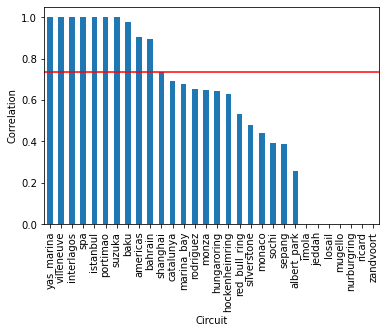

In [208]:
import pandas as pd
import matplotlib.pyplot as plt

# Filter the dataframe to only include races where pole position is 0.000
pole_positions = df[df['quali_gap'] == 0.000]

# Calculate the correlation between pole position and the winner for each circuit
correlations = -(pole_positions.groupby('circuit_id')['rank'].corr(pole_positions['target']))

# Sort the correlations in descending order
correlations = correlations.sort_values(ascending=False)
average_corr = correlations.mean()

# Plot the correlations as a bar chart
correlations.plot(kind='bar')
#plt.title('Correlation between pole position and race winner')
plt.axhline(y=average_corr, color='r', linestyle='-')
plt.xlabel('Circuit')
plt.ylabel('Correlation')
plt.show()

We can now create our initial Machine Learning Model. Before we to that, we need to set up a target. Our target will be wether the driver wins the grand prix or not. In our first model, we are going to allocate a 1 if the driver has win the GP, 0 otherwise.

In [28]:
df['target']= (df['rank']==1).astype('int')
df

/var/folders/81/tyt5gxcs48zfmfdm655lz3q40000gn/T/ipykernel_10773/197799905.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['target']= (df['rank']==1).astype('int')


,season,round,circuit_id,country,date,driver,nationality,constructor,grid,status,...,qualifying_time,Unnamed: 6,qualifying_time_diff,Top Team,team_id,numerical_circuit_id,driver_age,driver_id,status_id,target
17,2014,1,albert_park,Australia,2014-03-16,hamilton,British,mercedes,1,Engine,...,0.000,NaN,NaN,1,12,0,29,11,0,0
20,2014,1,albert_park,Australia,2014-03-16,ricciardo,Australian,red_bull,2,Disqualified,...,0.317,NaN,0.317,1,14,0,24,36,0,0
0,2014,1,albert_park,Australia,2014-03-16,rosberg,German,mercedes,3,Finished,...,0.364,NaN,0.047,1,12,0,28,37,1,1
1,2014,1,albert_park,Australia,2014-03-16,kevin_magnussen,Danish,mclaren,4,Finished,...,1.514,NaN,1.150,0,11,0,21,16,1,0
3,2014,1,albert_park,Australia,2014-03-16,alonso,Spanish,ferrari,5,Finished,...,1.588,NaN,0.074,1,5,0,32,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3188,2021,22,yas_marina,UAE,2021-12-12,vettel,German,aston_martin,15,Finished,...,2.196,NaN,0.054,0,3,28,34,48,1,0
3200,2021,22,yas_marina,UAE,2021-12-12,latifi,Canadian,williams,16,Accident,...,2.229,NaN,0.033,0,18,28,26,20,0,0
3199,2021,22,yas_marina,UAE,2021-12-12,russell,British,williams,17,Gearbox,...,2.314,NaN,0.085,0,18,28,23,39,0,0
3186,2021,22,yas_marina,UAE,2021-12-12,raikkonen,Finnish,alfa,18,Brakes,...,2.670,NaN,0.356,0,0,28,42,34,0,0


A random forest can pick the fact that a driver_id does not mean that if it's higher it's stronger, while a linear model can't.
A random forest is a serie of decision trees but each decision tree has slightly different parameters. 
The bigger n_estimators is, the longer the algorithm will take to run, but it will potentially be more accurate.
The bigger the min sample is, the less likely we are to overfit but the lower the accuracy on the training data will be. So we're gonna have to play with this value to get the best value possible. 
With random state we know we're gonna get the same results whenever we run the code. 

# b) Machine Learning Algorithms

Our dataset is time series data. 

# Random forest 

In [176]:
from sklearn.ensemble import RandomForestClassifier

depth = [1, 2, 3, 4, 5, 6, 7]
estimator = [80, 90, 100, 110, 120]
best = 0
var = [0, 0]
#Let's create our test set and training set
train = df[df['date'] < '2021-01-01']
test = df[df['date'] > '2021-01-01']
#predictors is a list of the predictions column that we created
predictors = ['teams_id','driver_id','status_id','quali_gap','grid','Top Team']
x_train= train[predictors]
y_train= train['target']
x_test= test[predictors]
y_test= test['target']

for i in depth : #max depth
    for j in estimator: #n_estimators
        RF = RandomForestClassifier(n_estimators=j, max_depth=i, random_state=0, bootstrap=True)
        RF.fit(x_train, y_train)
        y_pred = RF.predict(x_test)

        print(f'depth={i}, n_est={j}', accuracy_score(y_test, y_pred))
        
        if accuracy_score(y_test, y_pred) >= best:
            best = accuracy_score(y_test, y_pred)
            var=[i, j]

depth=1, n_est=80 0.9467787114845938
depth=1, n_est=90 0.9467787114845938
depth=1, n_est=100 0.9467787114845938
depth=1, n_est=110 0.9467787114845938
depth=1, n_est=120 0.9467787114845938
depth=2, n_est=80 0.9467787114845938
depth=2, n_est=90 0.9467787114845938
depth=2, n_est=100 0.9467787114845938
depth=2, n_est=110 0.9467787114845938
depth=2, n_est=120 0.9467787114845938
depth=3, n_est=80 0.9467787114845938
depth=3, n_est=90 0.9467787114845938
depth=3, n_est=100 0.9467787114845938
depth=3, n_est=110 0.9467787114845938
depth=3, n_est=120 0.9467787114845938
depth=4, n_est=80 0.9467787114845938
depth=4, n_est=90 0.9467787114845938
depth=4, n_est=100 0.9495798319327731
depth=4, n_est=110 0.9495798319327731
depth=4, n_est=120 0.9663865546218487
depth=5, n_est=80 0.9663865546218487
depth=5, n_est=90 0.9663865546218487
depth=5, n_est=100 0.9663865546218487
depth=5, n_est=110 0.9663865546218487
depth=5, n_est=120 0.9663865546218487
depth=6, n_est=80 0.9663865546218487
depth=6, n_est=90 0.966

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

params = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [3, 4, 5, 6, 7],
    'max_features': ['sqrt', 'log2'],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

train = df[df['date'] < '2021-01-01']
test = df[df['date'] > '2021-01-01']
predictors = ['teams_id','driver_id','status_id','quali_gap','grid']
x_train= train[predictors]
y_train= train['target']
x_test= test[predictors]
y_test= test['target']

rf = RandomForestClassifier()
clf = GridSearchCV(rf, params, cv=5)
clf.fit(x_train, y_train)

print(f'The best hyperparameters are: {clf.best_params_}')
print(f'The best accuracy is: {clf.best_score_:.3f}')

y_pred = clf.predict(x_test)
print(f'Test accuracy: {accuracy_score(y_test, y_pred):.3f}')

We are now going to calculate the accuracy of the model, thus we are going to see when we predict that a driver is going to win a grand prix, what's the probability that he actually wins.

In [177]:
best

0.9663865546218487

### The best accuracy is 96.64%

The thing is that the algorithm is certainly very good at predicting who is not going to win a race but not at who is actually gooing to win it.

In [112]:
#Combine actual values and predicted values

combine = pd.DataFrame(dict(actual=test['target'], prediction = f1_preds))
combine 

,actual,prediction
2783,0,1
2780,1,1
2777,0,0
2788,0,0
2787,0,0
...,...,...
3188,0,0
3200,0,0
3199,0,0
3186,0,0


So we are going to count the number of times the algorithm was right

In [118]:
confusion_matrix=pd.crosstab(index=combine['actual'], columns=combine['prediction'])
confusion_matrix

prediction,0,1
actual,,
0,327,11
1,7,12


0 = False & 1 = True in this confusion matrix

We notice that we are pretty good at predicting if a driver is not going to win a race 327 vs 7 , but quite bad at predicting if he's going to win. 12 vs 11

In [120]:
from sklearn.metrics import precision_score
precision_score(test['target'],f1_preds)

0.5217391304347826

When a driver win a race, the prediction is correct only 52% of the time.

c) Improving precision with rolling average

In [210]:
grouped_races=df.groupby('driver')
F1driver = grouped_races.get_group('hamilton')
F1driver

,season,round,circuit_id,country,date,driver,nationality,constructor,grid,status,...,quali_gap,Top Team,teams_id,Numerical Circuit ID,driver_age,team_id,numerical_circuit_id,driver_id,status_id,target
17,2014,1,albert_park,Australia,2014-03-16,hamilton,British,mercedes,1,Engine,...,0.000,1,12,0,29,12,0,11,0,0
39,2014,2,sepang,Malaysia,2014-03-30,hamilton,British,mercedes,1,Finished,...,0.000,1,12,21,29,12,21,11,1,1
61,2014,3,bahrain,Bahrain,2014-04-06,hamilton,British,mercedes,2,Finished,...,0.279,1,12,2,29,12,2,11,1,1
83,2014,4,shanghai,China,2014-04-20,hamilton,British,mercedes,1,Finished,...,0.000,1,12,22,29,12,22,11,1,1
105,2014,5,catalunya,Spain,2014-05-11,hamilton,British,mercedes,1,Finished,...,0.000,1,12,4,29,12,4,11,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3090,2021,17,americas,USA,2021-10-24,hamilton,British,mercedes,2,Finished,...,0.209,1,12,1,36,12,1,11,1,0
3110,2021,18,rodriguez,Mexico,2021-11-07,hamilton,British,mercedes,2,Finished,...,0.145,1,12,20,36,12,20,11,1,0
3149,2021,20,losail,Qatar,2021-11-21,hamilton,British,mercedes,1,Finished,...,0.000,1,12,11,36,12,11,11,1,1
3169,2021,21,jeddah,Saudi Arabia,2021-12-05,hamilton,British,mercedes,1,Finished,...,0.000,1,12,10,36,12,10,11,1,1


In [134]:
def rolling_averages(F1driver, columns, new_columns):
    F1driver=F1driver.sort_values('date')
    rolling_stats=F1driver[columns].rolling(3,closed='left').mean()
    F1driver[new_columns]=rolling_stats
    F1driver=F1driver.dropna(subset=new_columns)
    return F1driver

In [136]:
columns = ['quali_gap','status_id','rank','grid','driver_points','driver_wins','driver_standings_pos']
new_columns = [f'{x}_rolling' for x in columns]
rolling_averages(F1driver,columns,new_columns)

,season,round,circuit_id,country,date,driver,nationality,constructor,grid,status,...,driver_id,status_id,target,quali_gap_rolling,status_id_rolling,rank_rolling,grid_rolling,driver_points_rolling,driver_wins_rolling,driver_standings_pos_rolling
83,2014,4,shanghai,China,2014-04-20,hamilton,British,mercedes,1,Finished,...,11,1,1,0.093000,0.666667,7.000000,1.333333,8.333333,0.333333,7.000000
105,2014,5,catalunya,Spain,2014-05-11,hamilton,British,mercedes,1,Finished,...,11,1,1,0.093000,1.000000,1.000000,1.333333,25.000000,1.000000,7.666667
126,2014,6,monaco,Monaco,2014-05-25,hamilton,British,mercedes,2,Finished,...,11,1,0,0.093000,1.000000,1.000000,1.333333,50.000000,2.000000,2.000000
147,2014,7,villeneuve,Canada,2014-06-08,hamilton,British,mercedes,2,Brakes,...,11,0,0,0.019667,1.000000,1.333333,1.333333,75.000000,3.000000,1.666667
190,2014,9,silverstone,UK,2014-07-06,hamilton,British,mercedes,6,Finished,...,11,1,1,0.046000,0.666667,6.666667,1.666667,97.666667,3.666667,1.666667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3090,2021,17,americas,USA,2021-10-24,hamilton,British,mercedes,2,Finished,...,11,1,0,0.655000,1.000000,2.666667,5.666667,223.333333,4.333333,1.333333
3110,2021,18,rodriguez,Mexico,2021-11-07,hamilton,British,mercedes,2,Finished,...,11,1,0,0.712000,1.000000,2.666667,5.666667,241.333333,4.666667,1.666667
3149,2021,20,losail,Qatar,2021-11-21,hamilton,British,mercedes,1,Finished,...,11,1,1,0.074667,1.000000,3.000000,5.000000,259.333333,5.000000,1.666667
3169,2021,21,jeddah,Saudi Arabia,2021-12-05,hamilton,British,mercedes,1,Finished,...,11,1,1,0.118000,1.000000,1.666667,1.666667,283.333333,5.333333,2.000000


In [137]:
races_rolling=df.groupby('driver').apply(lambda x: rolling_averages(x, columns, new_columns))
races_rolling

season  round     circuit_id  country       date    driver  \
driver                                                                      
albon    2125    2019      5      catalunya    Spain 2019-05-12     albon   
         2145    2019      6         monaco   Monaco 2019-05-26     albon   
         2164    2019      7     villeneuve   Canada 2019-06-09     albon   
         2184    2019      8         ricard   France 2019-06-23     albon   
         2204    2019      9  red_bull_ring  Austria 2019-06-30     albon   
...               ...    ...            ...      ...        ...       ...   
wehrlein 1532    2017     16         suzuka    Japan 2017-10-08  wehrlein   
         1552    2017     17       americas      USA 2017-10-22  wehrlein   
         1571    2017     18      rodriguez   Mexico 2017-10-29  wehrlein   
         1590    2017     19     interlagos   Brazil 2017-11-12  wehrlein   
         1610    2017     20     yas_marina      UAE 2017-11-26  wehrlein   

              nationality constructor  grid            status  ...  driver_id  \
driver                                                         ...              
albon    2125        Thai  toro_rosso    11          Finished  ...          0   
         2145        Thai  toro_rosso    10          Finished  ...          0   
         2164        Thai  toro_rosso    13  Collision damage  ...          0   
         2184        Thai  toro_rosso    11            +1 Lap  ...          0   
         2204        Thai  toro_rosso    18            +1 Lap  ...          0   
...                   ...         ...   ...               ...  ...        ...   
wehrlein 1532      German      sauber    17           +2 Laps  ...         49   
         1552      German      sauber    14         Collision  ...         49   
         1571      German      sauber    13           +2 Laps  ...         49   
         1590      German      sauber    15            +1 Lap  ...         49   
         1610      German      sauber    18            +1 Lap  ...         49   

               status_id  target  quali_gap_rolling  status_id_rolling  \
driver                                                                   
albon    2125          1       0           1.932000           0.333333   
         2145          1       0           1.895000           0.666667   
         2164          0       0           1.841667           0.666667   
         2184          0       0           1.826333           0.666667   
         2204          0       0           1.860667           0.333333   
...                  ...     ...                ...                ...   
wehrlein 1532          0       0           5.098667           0.000000   
         1552          0       0           4.513667           0.000000   
         1571          0       0           4.014667           0.000000   
         1590          0       0           3.827333           0.000000   
         1610          0       0           3.090667           0.000000   

               rank_rolling  grid_rolling  driver_points_rolling  \
driver                                                             
albon    2125     11.333333     12.000000               1.000000   
         2145     10.333333     11.333333               2.000000   
         2164     10.000000     10.666667               3.000000   
         2184     12.666667     11.333333               4.333333   
         2204     14.000000     11.333333               5.666667   
...                     ...           ...                    ...   
wehrlein 1532     15.000000     16.333333               5.000000   
         1552     14.666667     18.000000               5.000000   
         1571     17.000000     16.333333               5.000000   
         1590     16.000000     14.666667               5.000000   
         1610     15.666667     14.000000               5.000000   

               driver_wins_rolling  driver_standings_pos_rolling  
driver                                      

We realise here that some drivers were not here during the whole hybrid era, some of them arrived and others disapeared

In [140]:
#We drop the driver column because it makes our work a little bit more complicated
races_rolling=races_rolling.droplevel('driver')

KeyError: 'Requested level (driver) does not match index name (None)'

In [141]:
races_rolling

,season,round,circuit_id,country,date,driver,nationality,constructor,grid,status,...,driver_id,status_id,target,quali_gap_rolling,status_id_rolling,rank_rolling,grid_rolling,driver_points_rolling,driver_wins_rolling,driver_standings_pos_rolling
2125,2019,5,catalunya,Spain,2019-05-12,albon,Thai,toro_rosso,11,Finished,...,0,1,0,1.932000,0.333333,11.333333,12.000000,1.000000,0.0,9.000000
2145,2019,6,monaco,Monaco,2019-05-26,albon,Thai,toro_rosso,10,Finished,...,0,1,0,1.895000,0.666667,10.333333,11.333333,2.000000,0.0,14.000000
2164,2019,7,villeneuve,Canada,2019-06-09,albon,Thai,toro_rosso,13,Collision damage,...,0,0,0,1.841667,0.666667,10.000000,10.666667,3.000000,0.0,14.333333
2184,2019,8,ricard,France,2019-06-23,albon,Thai,toro_rosso,11,+1 Lap,...,0,0,0,1.826333,0.666667,12.666667,11.333333,4.333333,0.0,14.666667
2204,2019,9,red_bull_ring,Austria,2019-06-30,albon,Thai,toro_rosso,18,+1 Lap,...,0,0,0,1.860667,0.333333,14.000000,11.333333,5.666667,0.0,14.666667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1532,2017,16,suzuka,Japan,2017-10-08,wehrlein,German,sauber,17,+2 Laps,...,49,0,0,5.098667,0.000000,15.000000,16.333333,5.000000,0.0,16.666667
1552,2017,17,americas,USA,2017-10-22,wehrlein,German,sauber,14,Collision,...,49,0,0,4.513667,0.000000,14.666667,18.000000,5.000000,0.0,17.333333
1571,2017,18,rodriguez,Mexico,2017-10-29,wehrlein,German,sauber,13,+2 Laps,...,49,0,0,4.014667,0.000000,17.000000,16.333333,5.000000,0.0,18.000000
1590,2017,19,interlagos,Brazil,2017-11-12,wehrlein,German,sauber,15,+1 Lap,...,49,0,0,3.827333,0.000000,16.000000,14.666667,5.000000,0.0,18.000000


Now we want to delete the rows that are repeated in the dataframe

In [144]:
races_rolling.index = range(races_rolling.shape[0])

Now let's retrain our new machine learning model

In [151]:
def new_prediction(data, predictors):
    train = data[data['date']<'2021-01-01']
    test = data[data['date']>'2021-01-01']
    rf.fit(train[predictors],train['target'])
    predictions = rf.predict(test[predictors])
    combine = pd.DataFrame(dict(actual=test['target'],predicted=predictions), index = test.index)
    precision = precision_score(test['target'],predictions)
    return (combine, precision)

In [152]:
combine, precision = new_prediction(races_rolling, predictors + new_columns)

In [154]:
precision

0.625

In [159]:
combine = combine.merge(races_rolling[['date','constructor','driver','rank']], left_index=True, right_index=True)
combine

,actual,predicted,date_x,constructor_x,driver_x,rank_x,date_y,constructor_y,driver_y,rank_y,date,constructor,driver,rank
120,0,0,2021-03-28,alpine,alonso,19,2021-03-28,alpine,alonso,19,2021-03-28,alpine,alonso,19
121,0,0,2021-04-18,alpine,alonso,10,2021-04-18,alpine,alonso,10,2021-04-18,alpine,alonso,10
122,0,0,2021-05-02,alpine,alonso,8,2021-05-02,alpine,alonso,8,2021-05-02,alpine,alonso,8
123,0,0,2021-05-09,alpine,alonso,17,2021-05-09,alpine,alonso,17,2021-05-09,alpine,alonso,17
124,0,0,2021-05-23,alpine,alonso,13,2021-05-23,alpine,alonso,13,2021-05-23,alpine,alonso,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2838,0,0,2021-10-24,aston_martin,vettel,10,2021-10-24,aston_martin,vettel,10,2021-10-24,aston_martin,vettel,10
2839,0,0,2021-11-07,aston_martin,vettel,7,2021-11-07,aston_martin,vettel,7,2021-11-07,aston_martin,vettel,7
2840,0,0,2021-11-21,aston_martin,vettel,10,2021-11-21,aston_martin,vettel,10,2021-11-21,aston_martin,vettel,10
2841,0,0,2021-12-05,aston_martin,vettel,16,2021-12-05,aston_martin,vettel,16,2021-12-05,aston_martin,vettel,16


# Gradient Boosting

In [165]:
from sklearn.ensemble import GradientBoostingClassifier

depth = [1, 2, 3, 4, 5, 6, 7]
estimator = [80, 90, 100, 110, 120]
learning_rate = [0.01, 0.05, 0.1, 0.5]
train = df[df['date'] < '2021-01-01']
test = df[df['date'] > '2021-01-01']
predictors = ['teams_id','driver_id','status_id','quali_gap','grid']
x_train= train[predictors]
y_train= train['target']
x_test= test[predictors]
y_test= test['target']



for i in depth : #max depth
    for j in estimator: #n_estimators
        for k in learning_rate: #learning rate
            GBC = GradientBoostingClassifier(loss='deviance',n_estimators=j, max_depth=i, learning_rate=k)
            GBC.fit(x_train, y_train)
            y_pred = GBC.predict(x_test)

            print(f'depth={i}, n_est={j}, rate={k}', accuracy_score(y_test, y_pred))
            
            best = 0
            var=[0, 0, 0]
            if accuracy_score(y_test, y_pred) > best:
                best = accuracy_score(y_test, y_pred)
                var=[i, j, k]

print(f'The best accuracy is {best} and is obtained for {var}')

depth=1, n_est=80, rate=0.01 0.9467787114845938
depth=1, n_est=80, rate=0.05 0.9495798319327731
depth=1, n_est=80, rate=0.1 0.9663865546218487
depth=1, n_est=80, rate=0.5 0.938375350140056
depth=1, n_est=90, rate=0.01 0.9467787114845938
depth=1, n_est=90, rate=0.05 0.9495798319327731
depth=1, n_est=90, rate=0.1 0.9663865546218487
depth=1, n_est=90, rate=0.5 0.938375350140056
depth=1, n_est=100, rate=0.01 0.9467787114845938
depth=1, n_est=100, rate=0.05 0.9663865546218487
depth=1, n_est=100, rate=0.1 0.9663865546218487
depth=1, n_est=100, rate=0.5 0.9551820728291317
depth=1, n_est=110, rate=0.01 0.9467787114845938
depth=1, n_est=110, rate=0.05 0.9663865546218487
depth=1, n_est=110, rate=0.1 0.9663865546218487
depth=1, n_est=110, rate=0.5 0.9551820728291317
depth=1, n_est=120, rate=0.01 0.9467787114845938
depth=1, n_est=120, rate=0.05 0.9663865546218487
depth=1, n_est=120, rate=0.1 0.9355742296918768
depth=1, n_est=120, rate=0.5 0.9551820728291317
depth=2, n_est=80, rate=0.01 0.946778711

In [233]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier

params = {
    'max_depth': [1, 2, 3, 4, 5, 6, 7],
    'n_estimators': [80, 90, 100, 110, 120],
    'learning_rate': [0.01, 0.05, 0.1, 0.5]
}

train = df[df['date'] < '2021-01-01']
test = df[df['date'] > '2021-01-01']
predictors = ['teams_id','driver_id','status_id','quali_gap','grid']
x_train= train[predictors]
y_train= train['target']
x_test= test[predictors]
y_test= test['target']

GBC = GradientBoostingClassifier(loss='deviance')
clf = GridSearchCV(GBC, params, cv=5)
clf.fit(x_train, y_train)

print(f'The best hyperparameters are: {clf.best_params_}')
print(f'The best accuracy is: {clf.best_score_:.3f}')

y_pred = clf.predict(x_test)
print(f'Test accuracy: {accuracy_score(y_test, y_pred):.3f}')

The best hyperparameters are: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 90}
The best accuracy is: 0.959
Test accuracy: 0.952


# ADABOOST

In [236]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import AdaBoostClassifier

params = {
    'n_estimators': [50, 100, 200, 300, 400],
    'learning_rate': [0.01, 0.05, 0.1, 0.5, 1]
}

train = df[df['date'] < '2021-01-01']
test = df[df['date'] > '2021-01-01']
predictors = ['teams_id','driver_id','status_id','quali_gap','grid']
x_train= train[predictors]
y_train= train['target']
x_test= test[predictors]
y_test= test['target']

ABC = AdaBoostClassifier()
clf = GridSearchCV(ABC, params, cv=5)
clf.fit(x_train, y_train)

print(f'The best hyperparameters are: {clf.best_params_}')
print(f'The best accuracy is: {clf.best_score_:.3f}')

y_pred = clf.predict(x_test)
print(f'Test accuracy: {accuracy_score(y_test, y_pred):.3f}')





The best hyperparameters are: {'learning_rate': 0.5, 'n_estimators': 50}
The best accuracy is: 0.961
Test accuracy: 0.952


# XG Boost

In [237]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier

params = {
    'max_depth': [3, 4, 5, 6, 7],
    'learning_rate': [0.01, 0.05, 0.1, 0.5],
    'n_estimators': [50, 100, 200, 300, 400],
    'subsample': [0.5, 0.6, 0.7, 0.8, 0.9],
    'colsample_bytree': [0.5, 0.6, 0.7, 0.8, 0.9]
}

train = df[df['date'] < '2021-01-01']
test = df[df['date'] > '2021-01-01']
predictors = ['teams_id','driver_id','status_id','quali_gap','grid']
x_train= train[predictors]
y_train= train['target']
x_test= test[predictors]
y_test= test['target']

xgb = XGBClassifier()
clf = GridSearchCV(xgb, params, cv=5)
clf.fit(x_train, y_train)

print(f'The best hyperparameters are: {clf.best_params_}')
print(f'The best accuracy is: {clf.best_score_:.3f}')

y_pred = clf.predict(x_test)
print(f'Test accuracy: {accuracy_score(y_test, y_pred):.3f}')

The best hyperparameters are: {'colsample_bytree': 0.6, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 50, 'subsample': 0.6}
The best accuracy is: 0.960
Test accuracy: 0.938


# CatBoost

In [173]:
!pip install catboost
import catboost as cb
from catboost import CatBoostClassifier

In [174]:
CB = CatBoostClassifier()
CB.fit(x_train, y_train)
y_pred = CB.predict(x_test)

print('Accuracy on test data:', CB.score(x_test, y_test))

Learning rate set to 0.015652
0:	learn: 0.6583971	total: 2.72ms	remaining: 2.72s
1:	learn: 0.6234728	total: 4.34ms	remaining: 2.17s
2:	learn: 0.5915292	total: 6.22ms	remaining: 2.07s
3:	learn: 0.5665555	total: 7.48ms	remaining: 1.86s
4:	learn: 0.5381457	total: 9.52ms	remaining: 1.89s
5:	learn: 0.5121280	total: 11.3ms	remaining: 1.88s
6:	learn: 0.4875176	total: 12.3ms	remaining: 1.75s
7:	learn: 0.4642479	total: 13.7ms	remaining: 1.7s
8:	learn: 0.4415481	total: 15ms	remaining: 1.65s
9:	learn: 0.4203993	total: 16ms	remaining: 1.58s
10:	learn: 0.4026596	total: 17.2ms	remaining: 1.54s
11:	learn: 0.3855736	total: 18.6ms	remaining: 1.53s
12:	learn: 0.3674421	total: 19.5ms	remaining: 1.48s
13:	learn: 0.3542585	total: 20.8ms	remaining: 1.46s
14:	learn: 0.3404817	total: 22.3ms	remaining: 1.47s
15:	learn: 0.3269244	total: 23.4ms	remaining: 1.44s
16:	learn: 0.3150105	total: 25ms	remaining: 1.45s
17:	learn: 0.3024923	total: 26.6ms	remaining: 1.45s
18:	learn: 0.2908431	total: 28.6ms	remaining: 1.48s

### The accuracy is equal to 65,58%

In [238]:
from sklearn.model_selection import GridSearchCV
from catboost import CatBoostClassifier

params = {
    'iterations': [100, 200, 300, 400],
    'learning_rate': [0.01, 0.05, 0.1, 0.5],
    'depth': [3, 4, 5, 6, 7],
    'l2_leaf_reg': [1, 3, 5, 7, 9],
    'random_strength': [0.1, 0.5, 1, 5, 10]
}

train = df[df['date'] < '2021-01-01']
test = df[df['date'] > '2021-01-01']
predictors = ['teams_id','driver_id','status_id','quali_gap','grid']
x_train= train[predictors]
y_train= train['target']
x_test= test[predictors]
y_test= test['target']

cat = CatBoostClassifier()
clf = GridSearchCV(cat, params, cv=5)
clf.fit(x_train, y_train, verbose=False)

print(f'The best hyperparameters are: {clf.best_params_}')
print(f'The best accuracy is: {clf.best_score_:.3f}')

y_pred = clf.predict(x_test)
print(f'Test accuracy: {accuracy_score(y_test, y_pred):.3f}')

The best hyperparameters are: {'depth': 5, 'iterations': 400, 'l2_leaf_reg': 7, 'learning_rate': 0.01, 'random_strength': 0.1}
The best accuracy is: 0.962
Test accuracy: 0.952


# Support Vector Machine

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

params = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma': ['scale', 'auto'] + list(range(1, 6)),
    'degree': [2, 3, 4]
}

train = df[df['date'] < '2021-01-01']
test = df[df['date'] > '2021-01-01']
predictors = ['teams_id','driver_id','status_id','quali_gap','grid']
x_train= train[predictors]
y_train= train['target']
x_test= test[predictors]
y_test= test['target']

svm = SVC()
clf = GridSearchCV(svm, params, cv=5)
clf.fit(x_train, y_train)

print(f'The best hyperparameters are: {clf.best_params_}')
print(f'The best accuracy is: {clf.best_score_:.3f}')

y_pred = clf.predict(x_test)
print(f'Test accuracy: {accuracy_score(y_test, y_pred):.3f}')

In [33]:
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from tqdm import tqdm

depth = [1, 2, 3, 4, 5, 6, 7]
iterations = [80, 90, 100, 110, 120]
learning_rate = [0.01, 0.05, 0.1, 0.5]
train = df[df['date'] < '2021-01-01']
test = df[df['date'] > '2021-01-01']
predictors = ['team_id','driver_id','status_id','quali_gap','grid','driver_points','driver_wins','driver_standings_pos','numerical_circuit_id']
x_train= train[predictors]
y_train= train['target']
x_test= test[predictors]
y_test= test['target']

best_accuracy = 0
best_model = None
best_confusion_matrix = None

for i in tqdm(depth, desc='Max depth'):
    for j in tqdm(iterations, desc='Iterations', leave=False):
        for k in tqdm(learning_rate, desc='Learning rate', leave=False):
            model = CatBoostClassifier(max_depth=i, iterations=j, learning_rate=k)
            model.fit(x_train, y_train, verbose=False)
            y_pred = model.predict(x_test)

            accuracy = accuracy_score(y_test, y_pred)

            if accuracy > best_accuracy:
                best_accuracy = accuracy
                best_model = model
                best_confusion_matrix = confusion_matrix(y_test, y_pred)

print(f"The best accuracy is {best_accuracy:.3f}")
print(f"The best model is {best_model}")
print(f"The best confusion matrix is:\n{best_confusion_matrix}")
print(f"The classification report is:\n{classification_report(y_test, y_pred)}")

Iterations:   0%|          | 0/5 [00:00<?, ?it/s]

Learning rate:   0%|          | 0/4 [00:00<?, ?it/s]

Learning rate:  25%|██▌       | 1/4 [00:00<00:00,  5.51it/s]

Learning rate:  75%|███████▌  | 3/4 [00:00<00:00, 11.74it/s]

                                                            
Iterations:  20%|██        | 1/5 [00:00<00:01,  2.69it/s]

Learning rate:   0%|          | 0/4 [00:00<?, ?it/s]

Learning rate:  50%|█████     | 2/4 [00:00<00:00, 16.42it/s]

Learning rate: 100%|██████████| 4/4 [00:00<00:00, 13.73it/s]

                                                            
Iterations:  40%|████      | 2/5 [00:00<00:01,  2.76it/s]

Learning rate:   0%|          | 0/4 [00:00<?, ?it/s]

Learning rate:  50%|█████     | 2/4 [00:00<00:00, 12.91it/s]

Learning rate: 100%|██████████| 4/4 [00:00<00:00, 11.18it/s]

                                                            
Iterations:  60%|██████    | 3/5 [00:01<00:00,  2.36it/s]

Learning rate:   0%|          | 0/4 [00:00<?, ?it/s]

L

The best accuracy is 0.972
The best model is <catboost.core.CatBoostClassifier object at 0x7f86be818d00>
The best confusion matrix is:
[[337   1]
 [  9  10]]
The classification report is:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       338
           1       0.69      0.58      0.63        19

    accuracy                           0.96       357
   macro avg       0.83      0.78      0.80       357
weighted avg       0.96      0.96      0.96       357



In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from tqdm import tqdm

depth = [1, 2, 3, 4, 5, 6, 7]
estimator = [80, 90, 100, 110, 120]
learning_rate = [0.01, 0.05, 0.1, 0.5]
train = df[df['date'] < '2021-01-01']
test = df[df['date'] > '2021-01-01']
predictors = ['team_id','driver_id','status_id','quali_gap','grid','driver_points','driver_wins','driver_standings_pos','status_id','numerical_circuit_id']
x_train= train[predictors]
y_train= train['target']
x_test= test[predictors]
y_test= test['target']

best_accuracy = 0
best_model = None
best_confusion_matrix = None

for i in tqdm(depth):
    for j in tqdm(estimator):
        for k in tqdm(learning_rate):
            GB = GradientBoostingClassifier(max_depth=i, n_estimators=j, learning_rate=k)
            GB.fit(x_train, y_train)
            y_pred = GB.predict(x_test)

            accuracy = accuracy_score(y_test, y_pred)

            if accuracy > best_accuracy:
                best_accuracy = accuracy
                best_model = GB
                best_confusion_matrix = confusion_matrix(y_test, y_pred)

print(f"The best accuracy is {best_accuracy:.3f}")
print(f"The best model is {best_model}")
print(f"The best confusion matrix is:\n{best_confusion_matrix}")
print(f"The classification report is:\n{classification_report(y_test, y_pred)}")